# Bônus — Treino multimodal em miniatura

O [AION-1](https://arxiv.org/abs/2510.17960) usa codificadores por modalidade e aprende com partes ocultas dos dados de diferentes levantamentos. Aqui fazemos uma **demonstração pequena inspirada nessa ideia**, usando a tabela do notebook 05. Este código não treina nem reproduz o AION; a amostra da aula é pequena demais para um foundation model científico.

## 1. Carregar a tabela

Execute o 05 primeiro. Cada linha tem campos escalares Gaia/DESI e três objetos com arrays: `image`, `spectrum` e `ztf_curves`. `read_pickle` deve ser usado somente para o arquivo confiável que acabamos de criar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

dataset = pd.read_pickle(Path("outputs/multimodal_dataset.pkl"))
print(f"Fontes completas: {len(dataset)}")
dataset[["object_id", "phot_g_mean_mag", "z", "spectype", "n_ztf_filters"]].head()

Fontes completas: 20


,object_id,phot_g_mean_mag,z,spectype,n_ztf_filters
0,gaia_2449852128778483328,20.980558,-0.000363,STAR,2
1,gaia_2449849315575044480,17.755526,-0.000430,STAR,2
2,gaia_2449851858195682944,17.429451,0.000121,STAR,2
3,gaia_2449850342071298048,21.327852,0.111139,GALAXY,2
4,gaia_2449845669146456576,18.827677,0.000258,STAR,2


## 2. Transformar cada modalidade em números de tamanho fixo

Um modelo recebe vetores, não DataFrames com arrays de tamanhos diferentes. Aqui reduzimos Gaia a 6 valores, o espectro a 16 amostras por braço, ZTF a 3 resumos por filtro e a imagem a 8×8 pixels. Isto perde detalhes; um modelo real usaria codificadores próprios para imagens, espectros e séries temporais.

In [2]:
def features(row):
    gaia = np.array([
        (row.phot_g_mean_mag - 18) / 5,
        (row.phot_bp_mean_mag - row.phot_rp_mean_mag) / 3,
        row.parallax / 5, row.pmra / 20, row.pmdec / 20, row.ruwe / 2,
    ], dtype=float)

    spectrum = []
    for arm in "brz":
        flux = np.asarray(row.spectrum[f"flux_{arm}"], dtype=float)
        ivar = np.asarray(row.spectrum[f"ivar_{arm}"], dtype=float)
        good = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
        signal = np.arcsinh(flux[good] / 10)
        samples = (np.interp(np.linspace(0, 1, 16),
                             np.linspace(0, 1, len(signal)), signal)
                   if len(signal) else np.zeros(16))
        spectrum.extend(samples)

    ztf = []
    curves = pd.DataFrame(row.ztf_curves)
    for band in (1, 2, 3):
        parts = curves[curves.filterid.eq(band)]
        mag = np.concatenate(parts.mag.to_numpy()).astype(float) if len(parts) else np.array([])
        mag = mag[np.isfinite(mag)]
        ztf.extend([(np.median(mag) - row.phot_g_mean_mag) / 5,
                    (np.percentile(mag, 95) - np.percentile(mag, 5)) / 2,
                    np.log1p(len(mag)) / 5] if len(mag) else [0, 0, 0])

    image = np.asarray(row.image, dtype=float)
    image = np.nan_to_num(image, nan=np.nanmedian(image))
    image = (image - np.median(image)) / (np.percentile(image, 95) - np.percentile(image, 5) + 1e-6)
    image = image.reshape(8, 16, 8, 16).mean(axis=(1, 3)).ravel()

    return [gaia, np.array(spectrum), np.array(ztf), image]

names = ["Gaia", "DESI", "ZTF", "S-PLUS"]
arrays = [features(row) for _, row in dataset.iterrows()]
modalities = [torch.tensor(np.nan_to_num(np.stack([row[i] for row in arrays]),
                                        posinf=0, neginf=0), dtype=torch.float32)
              for i in range(4)]
print(dict(zip(names, [tuple(x.shape) for x in modalities])))

{'Gaia': (20, 6), 'DESI': (20, 48), 'ZTF': (20, 9), 'S-PLUS': (20, 64)}


## 3. Esconder uma modalidade e tentar reconstruí-la

Cada vetor passa por uma camada linear. Um pequeno Transformer mistura as quatro representações. A cada passo, ocultamos uma modalidade inteira e calculamos o erro apenas nela. É uma versão didática da tarefa de **modelagem mascarada**; os resultados deste treino não medem desempenho astronômico.

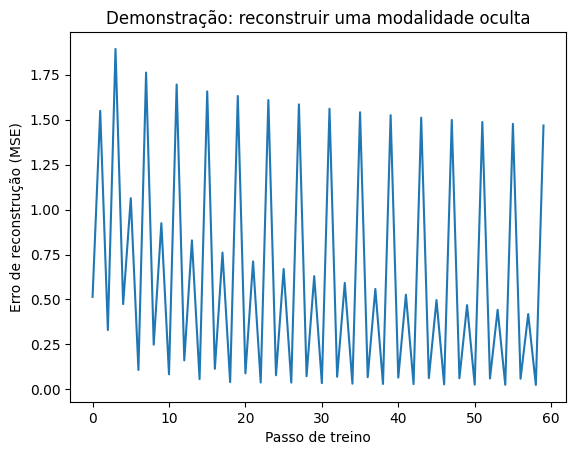

In [3]:
class MiniMultimodal(nn.Module):
    def __init__(self, sizes, width=32):
        super().__init__()
        self.encoders = nn.ModuleList(nn.Linear(size, width) for size in sizes)
        self.mask_tokens = nn.Parameter(torch.zeros(4, width))
        layer = nn.TransformerEncoderLayer(width, nhead=4, dim_feedforward=64,
                                           batch_first=True, dropout=0)
        self.transformer = nn.TransformerEncoder(layer, num_layers=2)
        self.decoders = nn.ModuleList(nn.Linear(width, size) for size in sizes)

    def forward(self, values, hidden):
        tokens = torch.stack([encoder(x) for encoder, x in zip(self.encoders, values)], dim=1)
        tokens[:, hidden] = self.mask_tokens[hidden]
        mixed = self.transformer(tokens)
        return self.decoders[hidden](mixed[:, hidden])

torch.manual_seed(7)
model = MiniMultimodal([x.shape[1] for x in modalities])
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
losses = []

for step in range(60):
    hidden = step % 4
    prediction = model(modalities, hidden)
    loss = nn.functional.mse_loss(prediction, modalities[hidden])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

plt.plot(losses)
plt.xlabel("Passo de treino")
plt.ylabel("Erro de reconstrução (MSE)")
plt.title("Demonstração: reconstruir uma modalidade oculta")
plt.show()

## O que mudaria em um foundation model?

Precisaríamos de muitos campos e objetos, divisão treino/teste por região do céu, tratamento explícito de medidas ausentes e incertezas, codificadores que preservem a resolução dos dados, validação em tarefas científicas e infraestrutura para treinar em escala. AION-1 usa tokenização própria por modalidade e modelagem mascarada multimodal em escala muito maior ([artigo](https://arxiv.org/abs/2510.17960), [código](https://github.com/PolymathicAI/AION)).